In [18]:
import torch

inputs = torch.tensor([
    [0.43, 0.15, 0.89],
    [0.55, 0.87, 0.66],
    [0.57, 0.85, 0.64],
    [0.22, 0.58, 0.33],
    [0.77, 0.25, 0.10],
    [0.05, 0.80, 0.55]
])

print(inputs.shape)
# torch.Size([6, 3])

torch.Size([6, 3])


In [19]:
## 3.3.2. Attention Scores bằng Dot Product
# Chọn từ thứ 2 trong câu làm vector query (truy vấn) để so sánh với toàn bộ các từ còn lại
query = inputs[1]
print("Vector Query (từ thứ 2):")
print(query)

# -------------------------------------------------------------------------
# Tính Attention Scores bằng phép nhân ma trận (tương đương với dùng vòng lặp for)
# Bản chất: Lấy vector query nhân vô hướng (dot product) với từng hàng trong inputs
# -------------------------------------------------------------------------
attn_scores_2 = inputs @ query

print("\nKết quả Attention Scores (mức độ liên quan của từ thứ 2 với các từ trong câu):")
print(attn_scores_2)

Vector Query (từ thứ 2):
tensor([0.5500, 0.8700, 0.6600])

Kết quả Attention Scores (mức độ liên quan của từ thứ 2 với các từ trong câu):
tensor([0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865])


In [20]:
## 3.3.3 Thay vì tính cho từng cái thì bây giờ ta nhân 1 phát cho cả cụm khỏi vòng for
scores = inputs @ inputs.T
print(scores.shape)
print(scores)

torch.Size([6, 6])
tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


In [21]:
## Sau khi có được cái scores này thì ta có thể dùng nó để tính attention cho từng từ trong câu với toàn bộ các từ còn lại.
## Dùng hàm softmax để chuẩn hóa các scores này thành xác suất attention.

weights = torch.softmax(scores, dim=1)
print(weights.shape)
print(weights)

torch.Size([6, 6])
tensor([[0.2098, 0.2006, 0.1981, 0.1242, 0.1220, 0.1452],
        [0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581],
        [0.1390, 0.2369, 0.2326, 0.1242, 0.1108, 0.1565],
        [0.1435, 0.2074, 0.2046, 0.1462, 0.1263, 0.1720],
        [0.1526, 0.1958, 0.1975, 0.1367, 0.1879, 0.1295],
        [0.1385, 0.2184, 0.2128, 0.1420, 0.0988, 0.1896]])


## Sau khi có weights, ta tạo context vector bằng tổng có trọng số:
$$
z_i=\sum_{j=1}^{T}\alpha_{ij}x_j
$$

In [22]:
context_vector = weights @ inputs
print(context_vector.shape)
print(context_vector)

torch.Size([6, 3])
tensor([[0.4421, 0.5931, 0.5790],
        [0.4419, 0.6515, 0.5683],
        [0.4431, 0.6496, 0.5671],
        [0.4304, 0.6298, 0.5510],
        [0.4671, 0.5910, 0.5266],
        [0.4177, 0.6503, 0.5645]])


## Phần 4 — Section 3.4: Implementing Self-Attention with Trainable Weights

Ở Section 3.3, ta tính:
$$
S=XX^\top
$$

Nhưng cách này chỉ so sánh trực tiếp các embedding ban đầu.
Ta muốn mô hình có khả năng học cách biểu diễn các token sao cho phù hợp với việc tìm kiếm, so khớp và tổng hợp thông tin.
Vì vậy, sách giới thiệu ba ma trận trọng số:
$$
W_Q,\ W_K,\ W_V
$$

4.2. Query, Key, Value
Ta tạo:
$$
Q=XW_Q
$$

$$
K=XW_K
$$

$$
V=XW_V
$$

Ý nghĩa:
Query: Biểu diễn thông tin mà token hiện tại cần tìm.
Key: Biểu diễn dùng để đánh giá token khác có phù hợp với Query hay không.


Query (Q): Token hiện tại đang tìm kiếm thông tin gì từ các token khác.
Key (K): Đặc trưng của mỗi token để Query so khớp, không phải keyword theo nghĩa từ khóa.
Value (V): Thông tin mà mỗi token cung cấp khi được Attention tổng hợp, không phải giá trị số của K.  
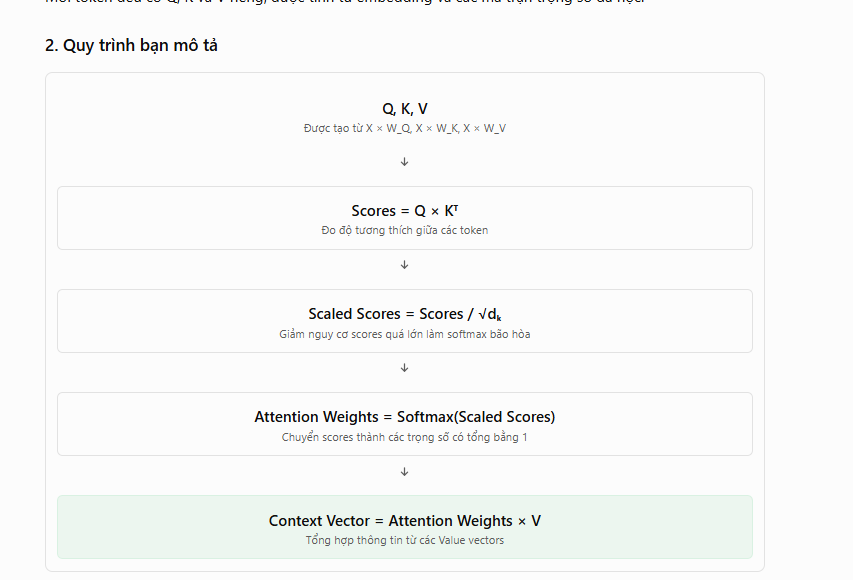  
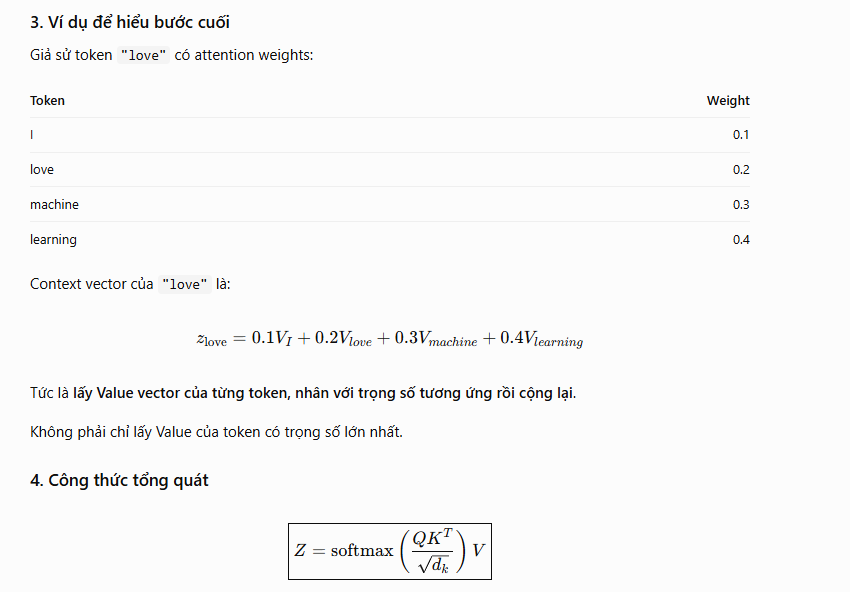  
. Công thức tổng quát
$$
\boxed{
Z=\operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V
}$$


In [23]:
torch.manual_seed(123)

d_in = 3
d_out = 2

print("d_in:", d_in)
print("d_out:", d_out)
print(inputs)

W_query = torch.nn.Parameter(torch.rand(d_in, d_out))
W_key = torch.nn.Parameter(torch.rand(d_in, d_out))
W_value = torch.nn.Parameter(torch.rand(d_in, d_out))

Q = inputs @ W_query
K = inputs @ W_key
V = inputs @ W_value

print(Q.shape, K.shape, V.shape)
print(Q, K, V)
# [6, 2] [6, 2] [6, 2]

d_in: 3
d_out: 2
tensor([[0.4300, 0.1500, 0.8900],
        [0.5500, 0.8700, 0.6600],
        [0.5700, 0.8500, 0.6400],
        [0.2200, 0.5800, 0.3300],
        [0.7700, 0.2500, 0.1000],
        [0.0500, 0.8000, 0.5500]])
torch.Size([6, 2]) torch.Size([6, 2]) torch.Size([6, 2])
tensor([[0.2309, 1.0966],
        [0.4306, 1.4551],
        [0.4300, 1.4343],
        [0.2355, 0.7990],
        [0.2983, 0.6565],
        [0.2568, 1.0533]], grad_fn=<MmBackward0>) tensor([[0.3669, 0.7646],
        [0.4433, 1.1419],
        [0.4361, 1.1156],
        [0.2408, 0.6706],
        [0.1827, 0.3292],
        [0.3275, 0.9642]], grad_fn=<MmBackward0>) tensor([[0.1855, 0.8812],
        [0.3951, 1.0037],
        [0.3879, 0.9831],
        [0.2393, 0.5493],
        [0.1492, 0.3346],
        [0.3221, 0.7863]], grad_fn=<MmBackward0>)


nn.Parameter giúp PyTorch đăng ký các tensor làm tham số học được khi chúng được gán làm thuộc tính của một nn.Module.

### 4.4. Attention Scores từ Q và K
Công thức:
$$
S=QK^\top
$$

In [24]:
scores = Q @ K.T

### 4.5. Tại sao phải chia cho căn bậc hai của d_k?
Công thức:
$$
S_{\text{scaled}}=\frac{QK^\top}{\sqrt{d_k}}
$$

Ở đây \(d_k\) là số chiều của Key.
Nếu các thành phần Q/K có phương sai gần 1 và tương đối độc lập, phương sai của dot product có thể tăng theo \(d_k\).
Khi scores có độ lớn quá cao, softmax dễ trở nên rất sắc nét và vùng gradient có thể bị bão hòa.
Chia cho \(\sqrt{d_k}\) giúp kiểm soát độ lớn scores.   
nói chung là do nó có thể lệch 1 cái quá lớn softmax nó ra lớn bất thưognf chia cho cái kia nhỏ lại như lấy trước softmax1 lần rồi mới softmax  


4.6. Công thức hoàn chỉnh
$$
\boxed{
Z=\operatorname{softmax}
\left(\frac{QK^\top}{\sqrt{d_k}}\right)V
}
$$

In [25]:
import torch
import torch.nn as nn

class SelfAttention_v1(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()

        self.W_query = nn.Parameter(torch.rand(d_in, d_out))
        self.W_key = nn.Parameter(torch.rand(d_in, d_out))
        self.W_value = nn.Parameter(torch.rand(d_in, d_out))

    def forward(self, x):
        Q = x @ self.W_query
        K = x @ self.W_key
        V = x @ self.W_value

        scores = Q @ K.T
        weights = torch.softmax(
            scores / K.shape[-1]**0.5,
            dim=-1
        )

        context = weights @ V
        return context

In [26]:
attention = SelfAttention_v1(3, 2)
output = attention(inputs)

print(output.shape)
# torch.Size([6, 2])

torch.Size([6, 2])


In [27]:
class SelfAttention_v2(nn.Module):
    def __init__(self, d_in, d_out, qkv_bias=False):
        super().__init__()

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

    def forward(self, x):
        Q = self.W_query(x)
        K = self.W_key(x)
        V = self.W_value(x)

        scores = Q @ K.T
        weights = torch.softmax(
            scores / K.shape[-1]**0.5,
            dim=-1
        )

        return weights @ V

### 4.9. nn.Linear khác nn.Parameter ở đâu?
nn.Parameter là một tensor được đăng ký làm tham số học được.
nn.Linear là một module triển khai phép biến đổi:
$$
y=xW^\top+b
$$

Trong PyTorch, nn.Linear(3, 2) lưu weight với shape [2, 3], trong khi cách nhân x @ W ở v1 sử dụng ma trận [3, 2].
Do đó, khi chuyển trọng số từ v2 sang v1, cần transpose.

### Phần 5 — Section 3.5: Hiding Future Words with Causal Attention
Đây là phần cực kỳ quan trọng đối với GPT vì GPT là mô hình autoregressive: dự đoán token tiếp theo dựa trên những token đã xuất hiện.

#### Giả sử chuỗi:
- I love machine learning


<pre>
Khi huấn luyện GPT để dự đoán token sau "I love", mô hình không được sử dụng thông tin từ "machine" hay "learning" ở những vị trí tương lai.
Nếu dùng Self-Attention không có mask, mọi vị trí có thể truy cập tất cả các vị trí khác. Điều đó làm rò rỉ thông tin đáp án trong quá trình huấn luyện next-token prediction.
Causal Attention giải quyết bằng cách giới hạn token tại vị trí i chỉ được truy cập các vị trí (j < i).
</pre>

#### 5.2. Causal Mask hoạt động thế nào?
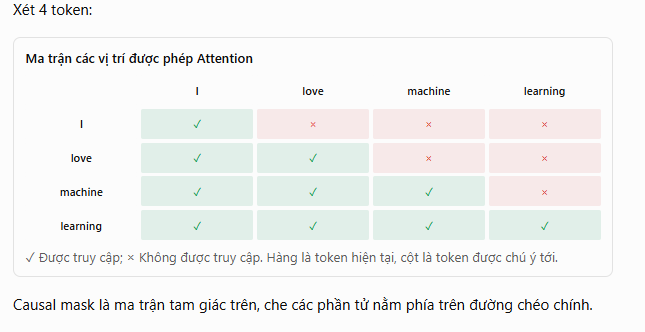

In [35]:
# Lấy tự động chiều dài chuỗi từ Q hoặc gán bằng 6
context_length = Q.shape[-2]  # Hoặc điền trực tiếp số 6

mask = torch.triu(
    torch.ones(context_length, context_length),
    diagonal=1
)

print(mask.shape)  # Lúc này sẽ in ra torch.Size([6, 6]) khớp với scores

torch.Size([6, 6])


### Có 2 cách biểu diển mask đó 1 là trước khi softmax, hoặc là sau softmax
- Cách 1: Mask sau Softmax
Đầu tiên tính attention weights, sau đó đặt các vị trí tương lai về 0 và chuẩn hóa lại.
Cách này hữu ích để hiểu ý tưởng nhưng phải chuẩn hóa lại vì tổng trọng số có thể nhỏ hơn 1.

- Cách 2: Mask trước Softmax
  Đây là cách hiệu quả hơn được sách sử dụng.
Thay các attention scores tương lai bằng âm vô cực:



là với lấy mask sau softmax thì nó là cho giá trị 0
Sau Softmax, các giá trị đã trở thành Attention Weights, tức là trọng số dùng để lấy thông tin từ Value vectors.
Ví dụ:
$$
\text{Weights}=[0.2,\ 0.3,\ 0.5]
$$

Nếu muốn che token thứ 3, ta đặt trọng số của nó bằng 0:
$$
[0.2,\ 0.3,\ \boxed{0}]
$$

Vì khi tính Context Vector:
$$
z=0.2V_1+0.3V_2+0V_3
$$  

Token thứ 3 sẽ không đóng góp thông tin.
Tuy nhiên, tổng trọng số còn 0.5 nên phải chuẩn hóa lại:
$$
[0.4,\ 0.6,\ 0]
$$  

2. Mask trước Softmax → Đặt bằng \(-\infty\)
Trước Softmax, các giá trị vẫn là Attention Scores, chưa phải trọng số.
Giả sử:
$$
\text{Scores}=[2,\ 3,\ 4]
$$

Nếu đặt score của token thứ 3 bằng 0:
$$
[2,\ 3,\ \boxed{0}]
$$

Khi đi qua Softmax:
$$
e^0=1
$$

Nghĩa là token thứ 3 vẫn có trọng số lớn hơn 0, nên vẫn đóng góp thông tin.
Vì vậy, đặt score bằng 0 không che hoàn toàn được token.
Thay vào đó, ta đặt:
$$
[2,\ 3,\ \boxed{-\infty}]
$$

Bởi vì:
$$
e^{-\infty}=0
$$

Khi qua Softmax:
$$
\operatorname{softmax}([2,3,-\infty])
\approx [0.269,\ 0.731,\ 0]
$$

Token thứ 3 lúc này thực sự bị che và Softmax tự chuẩn hóa hai trọng số còn lại.



=> kết quả 2 cách như nhau nhưng vì cách 2 lấy mask trước thì giảm bớt số bước và tính đỡn giản hơn nên người ta ưu tiên hơn

In [36]:
scores = Q @ K.T

masked_scores = scores.masked_fill(
    mask.bool(),
    float("-inf")
)

weights = torch.softmax(
    masked_scores / K.shape[-1]**0.5,
    dim=-1
)

### 5.5. Dropout trong Attention
thêm cái này vào giảm overfit

```
dropout = nn.Dropout(0.5)

weights = dropout(weights)
```


Dropout có thể ngẫu nhiên đặt một số attention weights về 0 trong training và scale các weights được giữ lại.

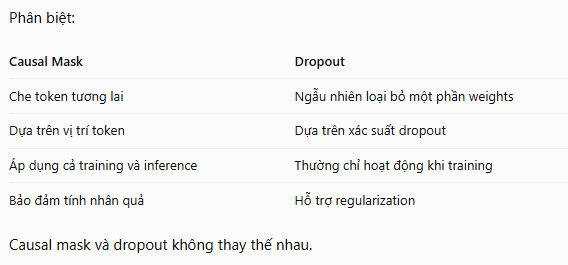

### 5.6. Batch Processing
Cho đến đây, các ví dụ chủ yếu sử dụng một chuỗi:
$$
X:[T,d_{in}]
$$
Khi huấn luyện thực tế, ta thường xử lý nhiều chuỗi cùng lúc:
$$
X:[B,T,d_{in}]
$$  

Trong đó:
- \(B=2\): số chuỗi trong batch.
- \(T=6\): số token mỗi chuỗi.
- \(d_{in}=3\): kích thước embedding.  
\[
Q,K,V\rightarrow Scores\rightarrow CausalMask\rightarrow Softmax\rightarrow Dropout\rightarrow Context
\]  

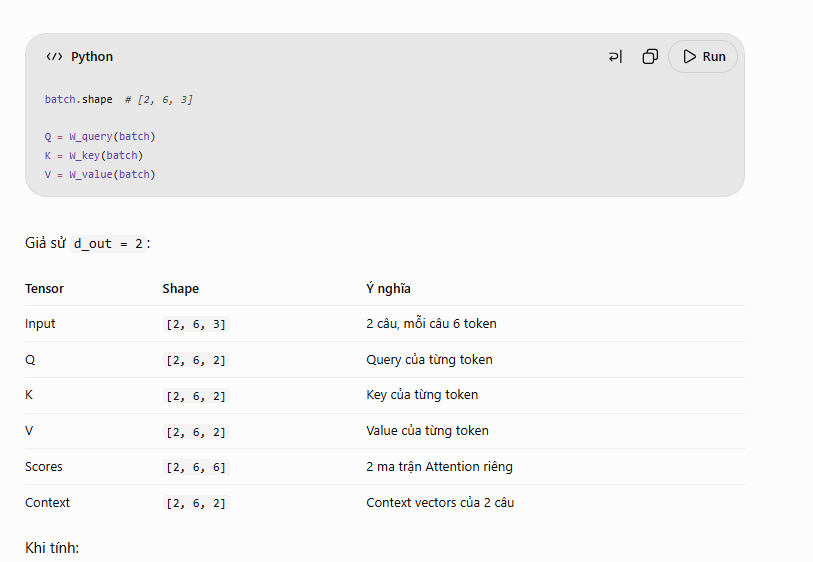

In [37]:
### Tự triển khai causal attention
import torch
import torch.nn as nn

class CausalAttention(nn.Module):
    def __init__(
        self,
        d_in,
        d_out,
        context_length,
        dropout,
        qkv_bias=False
    ):
        super().__init__()

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

        self.dropout = nn.Dropout(dropout)

        self.register_buffer(
            "mask",
            torch.triu(
                torch.ones(context_length, context_length),
                diagonal=1
            )
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape

        Q = self.W_query(x)
        K = self.W_key(x)
        V = self.W_value(x)

        scores = Q @ K.transpose(1, 2)

        scores.masked_fill_(
            self.mask.bool()[:num_tokens, :num_tokens],
            -torch.inf
        )

        weights = torch.softmax(
            scores / K.shape[-1]**0.5,
            dim=-1
        )

        weights = self.dropout(weights)

        context = weights @ V

        return context

In [39]:
batch = torch.stack((inputs, inputs), dim=0)

print(batch.shape)
# torch.Size([2, 6, 3])

torch.Size([2, 6, 3])


In [40]:
ca = CausalAttention(
    d_in=3,
    d_out=2,
    context_length=6,
    dropout=0.0
)

output = ca(batch)
print(output.shape)
# torch.Size([2, 6, 2])

torch.Size([2, 6, 2])


### resign buffer là gì


register_buffer đăng ký một tensor thuộc trạng thái module nhưng không phải tham số học được.  

Causal mask không cần gradient hay cập nhật bằng optimizer. Tuy nhiên, khi chuyển model sang GPU, mask cũng cần chuyển theo.  

register_buffer giúp quản lý việc đó.  

Bạn phải phân biệt:
- nn.Parameter: Tham số học được.
- register_buffer: Tensor trạng thái không được optimizer cập nhật.
- Tensor thường: Không tự động được quản lý như parameter/buffer nếu chỉ gán thành thuộc tính.  
- Tóm lại:
- register_buffer() → Quản lý tensor tốt hơn.
- reshape, transpose và phép nhân ma trận theo batch/head → Hỗ trợ tính Multi-Head Attention hiệu quả hơn.

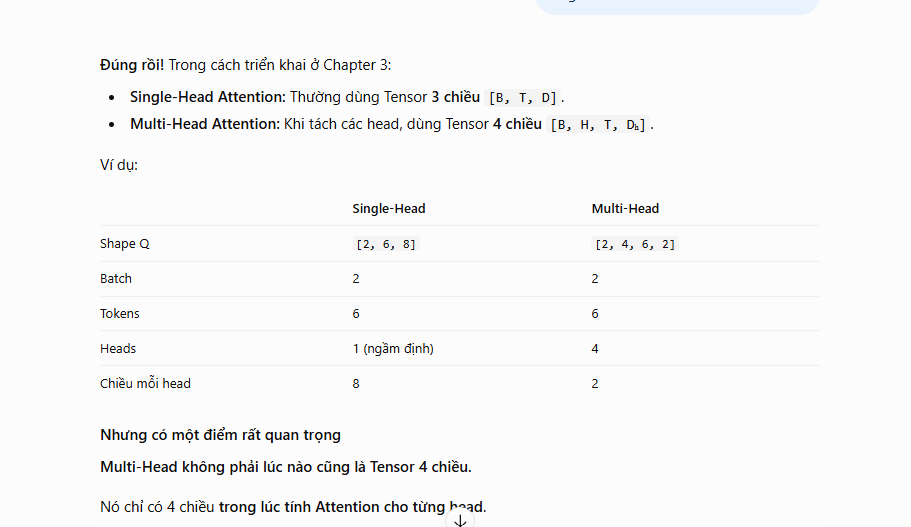

In [43]:
import torch
import torch.nn as nn

class CausalAttention(nn.Module):
    def __init__(
        self,
        d_in,
        d_out,
        context_length,
        dropout,
        qkv_bias=False
    ):
        super().__init__()

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

        self.dropout = nn.Dropout(dropout)

        self.register_buffer(
            "mask",
            torch.triu(
                torch.ones(context_length, context_length),
                diagonal=1
            )
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape

        Q = self.W_query(x)
        K = self.W_key(x)
        V = self.W_value(x)

        scores = Q @ K.transpose(1, 2)

        scores.masked_fill_(
            self.mask.bool()[:num_tokens, :num_tokens],
            -torch.inf
        )

        weights = torch.softmax(
            scores / K.shape[-1]**0.5,
            dim=-1
        )

        weights = self.dropout(weights)

        context = weights @ V

        return context

In [44]:
ca = CausalAttention(
    d_in=3,
    d_out=2,
    context_length=6,
    dropout=0.0
)

output = ca(batch)
print(output.shape)
# torch.Size([2, 6, 2])

torch.Size([2, 6, 2])


In [47]:
class MultiHeadAttention(nn.Module):
    def __init__(
        self,
        d_in,
        d_out,
        context_length,
        dropout,
        num_heads,
        qkv_bias=False
    ):
        super().__init__()

        assert d_out % num_heads == 0

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

        self.out_proj = nn.Linear(d_out, d_out)
        self.dropout = nn.Dropout(dropout)

        self.register_buffer(
            "mask",
            torch.triu(
                torch.ones(context_length, context_length),
                diagonal=1
            )
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape

        Q = self.W_query(x)
        K = self.W_key(x)
        V = self.W_value(x)

        Q = Q.view(
            b, num_tokens, self.num_heads, self.head_dim
        )
        K = K.view(
            b, num_tokens, self.num_heads, self.head_dim
        )
        V = V.view(
            b, num_tokens, self.num_heads, self.head_dim
        )

        Q = Q.transpose(1, 2)
        K = K.transpose(1, 2)
        V = V.transpose(1, 2)

        scores = Q @ K.transpose(2, 3)

        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]
        scores.masked_fill_(mask_bool, -torch.inf)

        weights = torch.softmax(
            scores / self.head_dim**0.5,
            dim=-1
        )

        weights = self.dropout(weights)

        context = weights @ V

        context = context.transpose(1, 2)
        context = context.contiguous().view(
            b, num_tokens, self.d_out
        )

        return self.out_proj(context)

In [48]:
mha = MultiHeadAttention(
    d_in=768,
    d_out=768,
    context_length=1024,
    dropout=0.1,
    num_heads=12
)

x = torch.randn(2, 6, 768)

output = mha(x)
print(output.shape)
# torch.Size([2, 6, 768])

torch.Size([2, 6, 768])


**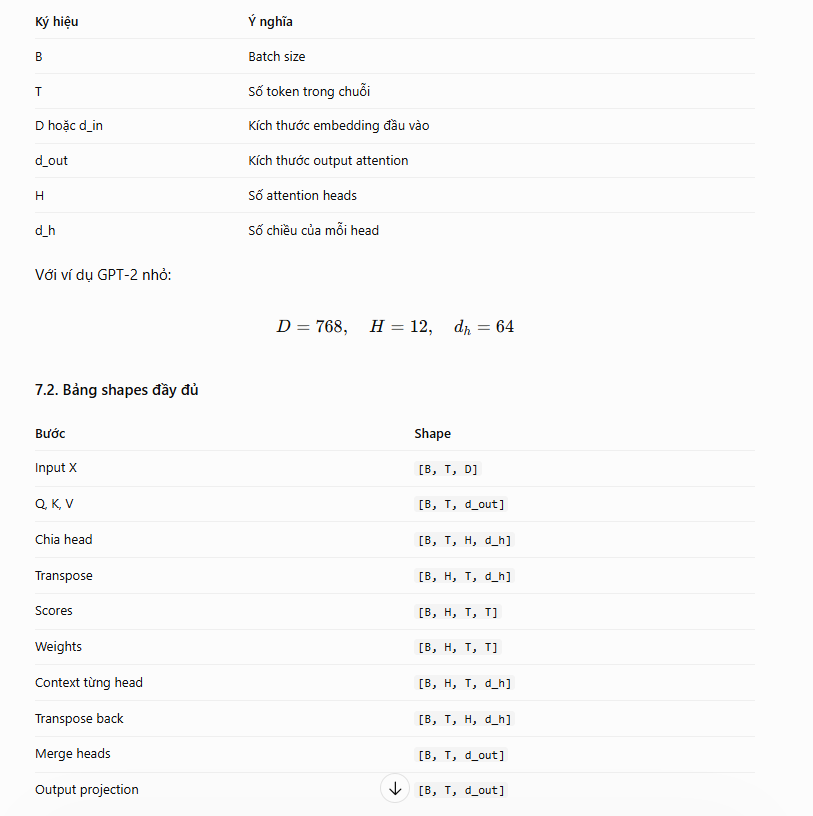**